In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv('state_CA.csv', dtype={'county_code': str}, low_memory=False)
sd = df[(df.county_code == '06073') & (df.action_taken.isin([1, 3]))]
sd.to_csv('hmda_2025_san_diego.csv', index=False)

In [5]:
df = pd.read_csv("hmda_2025_san_diego.csv", low_memory=False)

In [6]:
pd.set_option('display.max_rows', 200)
pd.set_option('display.max_columns', 200)

In [7]:
# df.head().T

In [8]:
# df.columns

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 68442 entries, 0 to 68441
Data columns (total 99 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   activity_year                             68442 non-null  int64  
 1   lei                                       68442 non-null  object 
 2   derived_msa-md                            68442 non-null  int64  
 3   state_code                                68442 non-null  object 
 4   county_code                               68442 non-null  int64  
 5   census_tract                              68374 non-null  float64
 6   conforming_loan_limit                     67929 non-null  object 
 7   derived_loan_product_type                 68442 non-null  object 
 8   derived_dwelling_category                 68442 non-null  object 
 9   derived_ethnicity                         68442 non-null  object 
 10  derived_race                      

In [10]:
for col in df.columns:
    print(col)
    print(df[col].unique()[:10])
    print()

activity_year
[2025]

lei
['549300LBCBNR1OT00651' '54930039IUN6515TBG78' '549300IRXW9RSZM2B951'
 '254900IRE136HFEI2562' '5493006LGHJCBICSE610' '549300UXTDELQS5SLF91'
 '254900378RFGMBEKAF12' '549300D003QRZFSQ4N43' '6PTKHDJ8HDUF78PFWH30'
 '5493003B2LEGQHDWRN55']

derived_msa-md
[41740]

state_code
['CA']

county_code
[6073]

census_tract
[6.07301910e+09 6.07302060e+09 6.07301002e+09 6.07300220e+09
 6.07302002e+09 6.07301681e+09 6.07301711e+09 6.07301030e+09
 6.07300920e+09 6.07300700e+09]

conforming_loan_limit
['C' 'NC' nan]

derived_loan_product_type
['VA:First Lien' 'Conventional:First Lien' 'FHA:First Lien'
 'Conventional:Subordinate Lien' 'FSA/RHS:First Lien'
 'VA:Subordinate Lien' 'FSA/RHS:Subordinate Lien' 'FHA:Subordinate Lien']

derived_dwelling_category
['Single Family (1-4 Units):Site-Built'
 'Single Family (1-4 Units):Manufactured' 'Multifamily:Site-Built'
 'Multifamily:Manufactured']

derived_ethnicity
['Joint' 'Not Hispanic or Latino' 'Ethnicity Not Available'
 'Hispanic or

In [11]:
df['approved'] = (df.action_taken == 1).astype(int)
df.approved.value_counts(normalize=True)

approved
1    0.767117
0    0.232883
Name: proportion, dtype: float64

In [12]:
leak = ['action_taken', 'purchaser_type', 'interest_rate', 'rate_spread', 'hoepa_status',
        'total_loan_costs', 'total_points_and_fees', 'origination_charges',
        'discount_points', 'lender_credits',
        'denial_reason-1', 'denial_reason-2', 'denial_reason-3', 'denial_reason-4']

constant = ['activity_year', 'state_code', 'county_code', 'derived_msa-md', 'census_tract']

protected = [c for c in df.columns 
             if c.startswith(('derived_', 'applicant', 'co-applicant'))
             and any(w in c for w in ['ethnicity', 'race', 'sex', 'age'])]


fairness = df[protected.copy()]
df = df.drop(columns=leak + constant + protected)
df.shape

(68442, 46)

In [13]:
df.isnull().sum().sort_values(ascending=False).head(20)

aus-5                             67830
multifamily_affordable_units      67808
aus-4                             67772
aus-3                             67075
prepayment_penalty_term           65910
aus-2                             62488
intro_rate_period                 47751
debt_to_income_ratio               7443
income                             5390
loan_to_value_ratio                4370
property_value                     2086
loan_term                          1153
conforming_loan_limit               513
derived_dwelling_category             0
business_or_commercial_purpose        0
loan_amount                           0
reverse_mortgage                      0
open-end_line_of_credit               0
lien_status                           0
loan_purpose                          0
dtype: int64

In [14]:
df.debt_to_income_ratio.value_counts().head(10)
df.property_value.dtype

dtype('O')

In [15]:
df.isnull().groupby(df.approved).mean().T

approved,0,1
lei,0.000000,0.000000
conforming_loan_limit,0.001694,0.009257
derived_loan_product_type,0.000000,0.000000
derived_dwelling_category,0.000000,0.000000
preapproval,0.000000,0.000000
loan_type,0.000000,0.000000
loan_purpose,0.000000,0.000000
lien_status,0.000000,0.000000
reverse_mortgage,0.000000,0.000000
open-end_line_of_credit,0.000000,0.000000


In [16]:
missing_share = df.isnull().mean()
missing_share.sort_values(ascending=False).head(20)

aus-5                             0.991058
multifamily_affordable_units      0.990737
aus-4                             0.990211
aus-3                             0.980027
prepayment_penalty_term           0.963005
aus-2                             0.913007
intro_rate_period                 0.697686
debt_to_income_ratio              0.108749
income                            0.078753
loan_to_value_ratio               0.063850
property_value                    0.030478
loan_term                         0.016846
conforming_loan_limit             0.007495
derived_dwelling_category         0.000000
business_or_commercial_purpose    0.000000
loan_amount                       0.000000
reverse_mortgage                  0.000000
open-end_line_of_credit           0.000000
lien_status                       0.000000
loan_purpose                      0.000000
dtype: float64

In [17]:
mostly_empty = list(missing_share[missing_share > 0.9].index)
single_value = [col for col in df.columns if df[col].nunique() == 1]
print('mostly empty:', mostly_empty)
print('single value:', single_value)

df = df.drop(columns=mostly_empty + single_value)
df.shape

mostly empty: ['prepayment_penalty_term', 'multifamily_affordable_units', 'aus-2', 'aus-3', 'aus-4', 'aus-5']
single value: ['ffiec_msa_md_median_family_income']


(68442, 39)

In [18]:
df.shape

(68442, 39)

In [19]:
df['is_adjustable'] = pd.to_numeric(df.intro_rate_period, errors='coerce').notnull().astype(int)
df= df.drop(columns=['intro_rate_period'])
df.is_adjustable.value_counts()

is_adjustable
0    47903
1    20539
Name: count, dtype: int64

In [20]:
for col in ['loan_to_value_ratio', 'loan_term','property_value']:
    df[col] = pd.to_numeric(df[col], errors='coerce')
    
df[['loan_amount', 'loan_to_value_ratio', 'loan_term', 'property_value', 'income']].describe().round(1)

,loan_amount,loan_to_value_ratio,loan_term,property_value,income
count,68442.0,63927.0,67139.0,66204.0,63052.0
mean,589590.0,832.1,332.3,1261807.0,272.4
std,1551314.6,193799.8,74.4,2643565.7,2747.1
min,5000.0,0.0,6.0,5000.0,-4841.0
25%,185000.0,50.1,360.0,755000.0,118.0
50%,465000.0,69.0,360.0,955000.0,179.0
75%,755000.0,80.0,360.0,1335000.0,271.0
max,203945000.0,49000000.0,480.0,320805000.0,538234.0


In [21]:
print('negative incomes:', (df.income < 0).sum())
print('LTV above 200:', (df.loan_to_value_ratio > 200).sum())

negative incomes: 73
LTV above 200: 20


In [22]:
df['income'] = df.income.clip(lower=0)
df.loc[df.loan_to_value_ratio > 200, 'loan_to_value_ratio'] = np.nan

df[['loan_amount', 'loan_to_value_ratio', 'loan_term', 'property_value', 'income']].describe().round(1)

,loan_amount,loan_to_value_ratio,loan_term,property_value,income
count,68442.0,63907.0,67139.0,66204.0,63052.0
mean,589590.0,65.2,332.3,1261807.0,272.9
std,1551314.6,22.7,74.4,2643565.7,2746.8
min,5000.0,0.0,6.0,5000.0,0.0
25%,185000.0,50.1,360.0,755000.0,118.0
50%,465000.0,69.0,360.0,955000.0,179.0
75%,755000.0,80.0,360.0,1335000.0,271.0
max,203945000.0,199.9,480.0,320805000.0,538234.0


In [23]:
df[['income', 'loan_to_value_ratio']].describe().round(1)

,income,loan_to_value_ratio
count,63052.0,63907.0
mean,272.9,65.2
std,2746.8,22.7
min,0.0,0.0
25%,118.0,50.1
50%,179.0,69.0
75%,271.0,80.0
max,538234.0,199.9


In [24]:
df['loan_type'] = df.loan_type.map({1:'conventional', 2: 'fha', 3: 'va', 4: 
    'usda'})
df['loan_purpose'] = df.loan_purpose.map({1: 'purchase', 2: 'improvement', 31: 'refinance', 32: 'cash_out_refi', 4: 'other', 5: 'na'})

df['occupancy_type'] = df.occupancy_type.map({1: 'primary_residence', 2: 'second_home', 3: 'investment_property'})
df['lien_status'] = df.lien_status.map({1: 'first', 2: 'second'})

code_columns = ['preapproval', 'reverse_mortgage', 'open-end_line_of_credit',
                'business_or_commercial_purpose', 'negative_amortization',
                'interest_only_payment', 'balloon_payment', 'other_nonamortizing_features',
                'construction_method', 'manufactured_home_secured_property_type',
                'manufactured_home_land_property_interest', 'applicant_credit_score_type',
                'co-applicant_credit_score_type', 'submission_of_application',
                'initially_payable_to_institution', 'aus-1']

for col in code_columns:
    df[col] = df[col].astype(str)
    
numerical = ['loan_amount', 'loan_to_value_ratio', 'loan_term', 'property_value', 'income',
             'is_adjustable', 'tract_population', 'tract_to_msa_income_percentage',
             'tract_owner_occupied_units', 'tract_one_to_four_family_homes',
             'tract_median_age_of_housing_units']

categorical = [col for col in df.columns
               if col not in numerical + ['approved', 'tract_minority_population_percent']]

print(len(numerical), 'numerical')
print(len(categorical), 'categorical:', categorical)



11 numerical
26 categorical: ['lei', 'conforming_loan_limit', 'derived_loan_product_type', 'derived_dwelling_category', 'preapproval', 'loan_type', 'loan_purpose', 'lien_status', 'reverse_mortgage', 'open-end_line_of_credit', 'business_or_commercial_purpose', 'negative_amortization', 'interest_only_payment', 'balloon_payment', 'other_nonamortizing_features', 'construction_method', 'occupancy_type', 'manufactured_home_secured_property_type', 'manufactured_home_land_property_interest', 'total_units', 'debt_to_income_ratio', 'applicant_credit_score_type', 'co-applicant_credit_score_type', 'submission_of_application', 'initially_payable_to_institution', 'aus-1']


In [25]:
df

,lei,conforming_loan_limit,derived_loan_product_type,derived_dwelling_category,preapproval,loan_type,loan_purpose,lien_status,reverse_mortgage,open-end_line_of_credit,business_or_commercial_purpose,loan_amount,loan_to_value_ratio,loan_term,negative_amortization,interest_only_payment,balloon_payment,other_nonamortizing_features,property_value,construction_method,occupancy_type,manufactured_home_secured_property_type,manufactured_home_land_property_interest,total_units,income,debt_to_income_ratio,applicant_credit_score_type,co-applicant_credit_score_type,submission_of_application,initially_payable_to_institution,aus-1,tract_population,tract_minority_population_percent,tract_to_msa_income_percentage,tract_owner_occupied_units,tract_one_to_four_family_homes,tract_median_age_of_housing_units,approved,is_adjustable
0,549300LBCBNR1OT00651,C,VA:First Lien,Single Family (1-4 Units):Site-Built,2,va,purchase,first,2,2,2,685000.0,NaN,359.0,2,2,2,2,655000.0,1,primary_residence,3,5,1,157.0,36,2,9,1,1,1,7046,41.68,103,1628,2220,32,0,0
1,549300LBCBNR1OT00651,C,Conventional:First Lien,Single Family (1-4 Units):Site-Built,2,conventional,refinance,first,2,2,2,375000.0,NaN,307.0,2,2,2,2,535000.0,1,primary_residence,3,5,1,288.0,20%-<30%,1,9,1,1,2,5970,61.44,66,902,1470,48,1,0
2,549300LBCBNR1OT00651,C,VA:First Lien,Single Family (1-4 Units):Site-Built,2,va,purchase,first,2,2,2,615000.0,NaN,360.0,2,2,2,2,655000.0,1,primary_residence,3,5,1,139.0,50%-60%,1,10,1,1,1,5818,89.05,117,1089,1266,16,1,0
3,549300LBCBNR1OT00651,C,VA:First Lien,Single Family (1-4 Units):Site-Built,2,va,purchase,first,2,2,2,755000.0,NaN,320.0,2,2,2,2,795000.0,1,primary_residence,3,5,1,161.0,46,1,9,1,1,1,3593,87.70,42,412,741,45,1,0
4,549300LBCBNR1OT00651,C,VA:First Lien,Single Family (1-4 Units):Site-Built,2,va,purchase,first,2,2,2,505000.0,NaN,329.0,2,2,2,2,515000.0,1,primary_residence,3,5,1,124.0,50%-60%,1,9,1,1,1,5021,55.95,84,957,1119,38,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68437,549300LBCBNR1OT00651,C,VA:First Lien,Single Family (1-4 Units):Site-Built,2,va,other,first,2,2,2,455000.0,NaN,352.0,2,2,2,2,NaN,1,primary_residence,3,5,1,NaN,NaN,9,9,1,1,6,4615,87.74,90,644,1092,50,1,0
68438,549300LBCBNR1OT00651,C,Conventional:First Lien,Single Family (1-4 Units):Site-Built,2,conventional,other,first,2,2,2,335000.0,NaN,290.0,2,2,2,2,NaN,1,primary_residence,3,5,1,NaN,NaN,9,9,1,1,6,3184,52.70,92,283,302,43,1,0
68439,549300LBCBNR1OT00651,C,Conventional:First Lien,Single Family (1-4 Units):Site-Built,2,conventional,refinance,first,2,2,2,455000.0,NaN,298.0,2,2,2,2,585000.0,1,primary_residence,3,5,1,91.0,50%-60%,3,9,1,1,2,6806,30.11,135,1468,2355,35,0,0
68440,549300LBCBNR1OT00651,C,VA:First Lien,Single Family (1-4 Units):Site-Built,2,va,purchase,first,2,2,2,695000.0,NaN,311.0,2,2,2,2,775000.0,1,primary_residence,3,5,1,269.0,30%-<36%,3,9,1,1,1,5470,29.63,108,1300,1643,42,1,0


In [26]:
for col in categorical:
    rates = df.groupby(col).approved.agg(['mean','count'])
    suspicious = rates[(rates['mean'].isin([0, 1])) & (rates['count'] >= 500)]
    if len(suspicious) > 0:
        print(col)
        print('----')
        print(suspicious)
        print()


preapproval
----
             mean  count
preapproval             
1             1.0   1095

initially_payable_to_institution
----
                                  mean  count
initially_payable_to_institution             
3                                  0.0   2772



In [27]:
df = df.drop(columns=['initially_payable_to_institution', 'preapproval'])
categorical.remove('initially_payable_to_institution')
categorical.remove('preapproval')
df.shape, len(categorical)

((68442, 37), 24)

In [28]:
from sklearn.model_selection import train_test_split

In [29]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

len(df_train), len(df_val), len(df_test)

(41064, 13689, 13689)

In [30]:
df_full_train = df_full_train.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [31]:
for d in [df_full_train, df_train, df_val, df_test]:
    d[categorical] = d[categorical].fillna('missing')
    
df_full_train[categorical].isnull().sum()
df_train[categorical].isnull().sum()
df_val[categorical].isnull().sum()
df_test[categorical].isnull().sum()

lei                                         0
conforming_loan_limit                       0
derived_loan_product_type                   0
derived_dwelling_category                   0
loan_type                                   0
loan_purpose                                0
lien_status                                 0
reverse_mortgage                            0
open-end_line_of_credit                     0
business_or_commercial_purpose              0
negative_amortization                       0
interest_only_payment                       0
balloon_payment                             0
other_nonamortizing_features                0
construction_method                         0
occupancy_type                              0
manufactured_home_secured_property_type     0
manufactured_home_land_property_interest    0
total_units                                 0
debt_to_income_ratio                        0
applicant_credit_score_type                 0
co-applicant_credit_score_type    

In [32]:
df.columns

Index(['lei', 'conforming_loan_limit', 'derived_loan_product_type',
       'derived_dwelling_category', 'loan_type', 'loan_purpose', 'lien_status',
       'reverse_mortgage', 'open-end_line_of_credit',
       'business_or_commercial_purpose', 'loan_amount', 'loan_to_value_ratio',
       'loan_term', 'negative_amortization', 'interest_only_payment',
       'balloon_payment', 'other_nonamortizing_features', 'property_value',
       'construction_method', 'occupancy_type',
       'manufactured_home_secured_property_type',
       'manufactured_home_land_property_interest', 'total_units', 'income',
       'debt_to_income_ratio', 'applicant_credit_score_type',
       'co-applicant_credit_score_type', 'submission_of_application', 'aus-1',
       'tract_population', 'tract_minority_population_percent',
       'tract_to_msa_income_percentage', 'tract_owner_occupied_units',
       'tract_one_to_four_family_homes', 'tract_median_age_of_housing_units',
       'approved', 'is_adjustable'],
      dt

In [33]:
y_train = df_train.approved.values
y_val = df_val.approved.values
y_test = df_test.approved.values

In [34]:
del df_train['approved']
del df_val['approved']
del df_test['approved']

In [35]:
df_full_train = df_full_train.reset_index(drop=True)

In [36]:
df_full_train[categorical].isnull().sum()

lei                                         0
conforming_loan_limit                       0
derived_loan_product_type                   0
derived_dwelling_category                   0
loan_type                                   0
loan_purpose                                0
lien_status                                 0
reverse_mortgage                            0
open-end_line_of_credit                     0
business_or_commercial_purpose              0
negative_amortization                       0
interest_only_payment                       0
balloon_payment                             0
other_nonamortizing_features                0
construction_method                         0
occupancy_type                              0
manufactured_home_secured_property_type     0
manufactured_home_land_property_interest    0
total_units                                 0
debt_to_income_ratio                        0
applicant_credit_score_type                 0
co-applicant_credit_score_type    

In [37]:
df_full_train.approved.value_counts(normalize=True)

approved
1    0.767501
0    0.232499
Name: proportion, dtype: float64

In [38]:
approval_rate = df_full_train.approved.mean().round(3)
df_full_train[categorical].nunique()

lei                                         640
conforming_loan_limit                         3
derived_loan_product_type                     8
derived_dwelling_category                     4
loan_type                                     4
loan_purpose                                  6
lien_status                                   2
reverse_mortgage                              3
open-end_line_of_credit                       3
business_or_commercial_purpose                3
negative_amortization                         3
interest_only_payment                         3
balloon_payment                               3
other_nonamortizing_features                  3
construction_method                           2
occupancy_type                                3
manufactured_home_secured_property_type       4
manufactured_home_land_property_interest      6
total_units                                   9
debt_to_income_ratio                         21
applicant_credit_score_type             

In [39]:
from IPython.display import display

for col in ['loan_purpose', 'loan_type', 'occupancy_type', 'lien_status']:
    rates = df_full_train.groupby(col).approved.agg(['mean', 'count'])
    rates['diff'] = rates['mean'] - approval_rate
    rates['ratio'] = rates['mean'] / approval_rate
    display(rates.sort_values('mean').round(3))
    

,mean,count,diff,ratio
loan_purpose,,,,
other,0.577,6688,-0.191,0.751
improvement,0.652,7472,-0.116,0.849
cash_out_refi,0.726,10842,-0.042,0.946
refinance,0.805,10438,0.037,1.048
purchase,0.881,19291,0.113,1.147
na,0.955,22,0.187,1.243


,mean,count,diff,ratio
loan_type,,,,
conventional,0.757,46164,-0.011,0.986
fha,0.773,3285,0.005,1.006
va,0.852,5294,0.084,1.110
usda,1.000,10,0.232,1.302


,mean,count,diff,ratio
occupancy_type,,,,
second_home,0.746,808,-0.022,0.972
primary_residence,0.766,48002,-0.002,0.997
investment_property,0.783,5943,0.015,1.020


,mean,count,diff,ratio
lien_status,,,,
second,0.651,19441,-0.117,0.847
first,0.832,35312,0.064,1.083


## Approval

The highest approval rates are:
- loan purpose -> purchase ("na" is higher but only 22 loans vs 19,291 for purchase)
- loan type -> VA
- occupancy type -> investment property
- lien status -> first lien


In [40]:
df

,lei,conforming_loan_limit,derived_loan_product_type,derived_dwelling_category,loan_type,loan_purpose,lien_status,reverse_mortgage,open-end_line_of_credit,business_or_commercial_purpose,loan_amount,loan_to_value_ratio,loan_term,negative_amortization,interest_only_payment,balloon_payment,other_nonamortizing_features,property_value,construction_method,occupancy_type,manufactured_home_secured_property_type,manufactured_home_land_property_interest,total_units,income,debt_to_income_ratio,applicant_credit_score_type,co-applicant_credit_score_type,submission_of_application,aus-1,tract_population,tract_minority_population_percent,tract_to_msa_income_percentage,tract_owner_occupied_units,tract_one_to_four_family_homes,tract_median_age_of_housing_units,approved,is_adjustable
0,549300LBCBNR1OT00651,C,VA:First Lien,Single Family (1-4 Units):Site-Built,va,purchase,first,2,2,2,685000.0,NaN,359.0,2,2,2,2,655000.0,1,primary_residence,3,5,1,157.0,36,2,9,1,1,7046,41.68,103,1628,2220,32,0,0
1,549300LBCBNR1OT00651,C,Conventional:First Lien,Single Family (1-4 Units):Site-Built,conventional,refinance,first,2,2,2,375000.0,NaN,307.0,2,2,2,2,535000.0,1,primary_residence,3,5,1,288.0,20%-<30%,1,9,1,2,5970,61.44,66,902,1470,48,1,0
2,549300LBCBNR1OT00651,C,VA:First Lien,Single Family (1-4 Units):Site-Built,va,purchase,first,2,2,2,615000.0,NaN,360.0,2,2,2,2,655000.0,1,primary_residence,3,5,1,139.0,50%-60%,1,10,1,1,5818,89.05,117,1089,1266,16,1,0
3,549300LBCBNR1OT00651,C,VA:First Lien,Single Family (1-4 Units):Site-Built,va,purchase,first,2,2,2,755000.0,NaN,320.0,2,2,2,2,795000.0,1,primary_residence,3,5,1,161.0,46,1,9,1,1,3593,87.70,42,412,741,45,1,0
4,549300LBCBNR1OT00651,C,VA:First Lien,Single Family (1-4 Units):Site-Built,va,purchase,first,2,2,2,505000.0,NaN,329.0,2,2,2,2,515000.0,1,primary_residence,3,5,1,124.0,50%-60%,1,9,1,1,5021,55.95,84,957,1119,38,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68437,549300LBCBNR1OT00651,C,VA:First Lien,Single Family (1-4 Units):Site-Built,va,other,first,2,2,2,455000.0,NaN,352.0,2,2,2,2,NaN,1,primary_residence,3,5,1,NaN,NaN,9,9,1,6,4615,87.74,90,644,1092,50,1,0
68438,549300LBCBNR1OT00651,C,Conventional:First Lien,Single Family (1-4 Units):Site-Built,conventional,other,first,2,2,2,335000.0,NaN,290.0,2,2,2,2,NaN,1,primary_residence,3,5,1,NaN,NaN,9,9,1,6,3184,52.70,92,283,302,43,1,0
68439,549300LBCBNR1OT00651,C,Conventional:First Lien,Single Family (1-4 Units):Site-Built,conventional,refinance,first,2,2,2,455000.0,NaN,298.0,2,2,2,2,585000.0,1,primary_residence,3,5,1,91.0,50%-60%,3,9,1,2,6806,30.11,135,1468,2355,35,0,0
68440,549300LBCBNR1OT00651,C,VA:First Lien,Single Family (1-4 Units):Site-Built,va,purchase,first,2,2,2,695000.0,NaN,311.0,2,2,2,2,775000.0,1,primary_residence,3,5,1,269.0,30%-<36%,3,9,1,1,5470,29.63,108,1300,1643,42,1,0


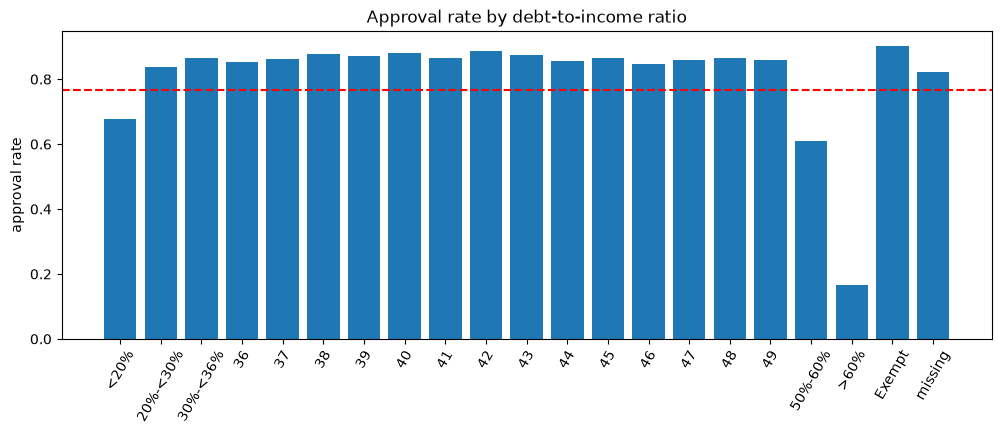

In [41]:
dti_order = ['<20%', '20%-<30%', '30%-<36%'] + [str(i) for i in range(36, 50)] + ['50%-60%', '>60%', 'Exempt', 'missing']

rates = df_full_train.groupby('debt_to_income_ratio').approved.mean()
rates = rates.reindex(dti_order)

plt.figure(figsize=(12, 4))
plt.bar(rates.index, rates.values)
plt.axhline(approval_rate, color='red', linestyle='--')
plt.xticks(rotation=60)
plt.ylabel('approval rate')
plt.title('Approval rate by debt-to-income ratio')
plt.show()

In [42]:
from sklearn.metrics import mutual_info_score

def mutual_info_approved(series):
    return mutual_info_score(series,df_full_train.approved)

mi = df_full_train[categorical].apply(mutual_info_approved)
mi.sort_values(ascending=False).round(4)

debt_to_income_ratio                        0.0949
lei                                         0.0791
loan_purpose                                0.0320
aus-1                                       0.0239
derived_loan_product_type                   0.0213
lien_status                                 0.0203
applicant_credit_score_type                 0.0177
open-end_line_of_credit                     0.0112
co-applicant_credit_score_type              0.0109
manufactured_home_secured_property_type     0.0040
manufactured_home_land_property_interest    0.0040
derived_dwelling_category                   0.0039
submission_of_application                   0.0033
construction_method                         0.0030
loan_type                                   0.0024
conforming_loan_limit                       0.0024
interest_only_payment                       0.0021
total_units                                 0.0012
reverse_mortgage                            0.0008
balloon_payment                

In [43]:
df_full_train[numerical].corrwith(df_full_train.approved).sort_values().round(3)

is_adjustable                       -0.057
tract_population                     0.001
tract_median_age_of_housing_units    0.004
income                               0.010
property_value                       0.013
tract_one_to_four_family_homes       0.017
tract_owner_occupied_units           0.018
loan_term                            0.021
tract_to_msa_income_percentage       0.037
loan_amount                          0.062
loan_to_value_ratio                  0.097
dtype: float64

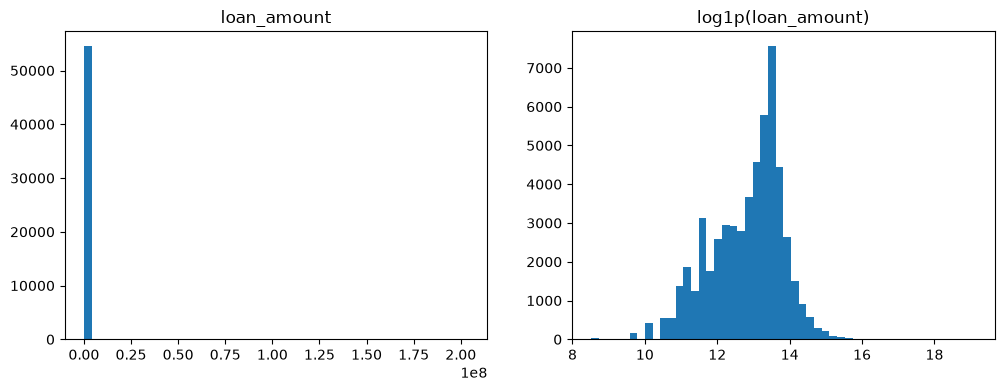

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df_full_train.loan_amount, bins=50)
axes[0].set_title('loan_amount')
axes[1].hist(np.log1p(df_full_train.loan_amount), bins=50)
axes[1].set_title('log1p(loan_amount)')
plt.show()

In [ ]:
# y_full_train = df_full_train.approved.values

# medians = df_train[numerical].median()

# for d in [df_full_train, df_train, df_val, df_test]:
#     d[numerical] = d[numerical].fillna(medians)
#     for col in ['loan_amount', 'property_value', 'income']:
#         d[col] = np.log1p(d[col])

# df_train[numerical].isnull().sum().sum()

np.int64(0)

In [58]:
from sklearn.feature_extraction import DictVectorizer

dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)


In [59]:
# dv.get_feature_names_out()

In [60]:
val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

In [61]:
X_train.shape, X_val.shape

((41064, 735), (13689, 735))

In [62]:
from sklearn.linear_model import LogisticRegression

In [64]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=1)
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1